In [1]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

import astropy.units as u
import astropy.constants as const
from galpy.orbit import Orbit
from galpy.util import conversion

from galpy.potential import vcirc
from galpy.potential import SCFPotential, scf_compute_coeffs_nbody
from galpy.potential import interpSphericalPotential
from galpy.potential import evaluatePotentials
from galpy.potential import evaluateDensities
from galpy.potential import (PlummerPotential, EinastoPotential,
                             TruncatedNFWPotential, TruncatedHernquistPotential)

/home/kovdnbra/anaconda3/envs/TANA/lib/python3.14/site-packages/galpy/potential/SCFPotential.py:1202: UserWarning: 'where' used without 'out', expect uninitialized memory in output. If this is intentional, use out=None.
  out = numpy.divide((r / a - 1.0), (r / a + 1.0), where=True ^ numpy.isinf(r))

/tmp/ipykernel_3280/2737330964.py:97: UserWarning: The figure layout has changed to tight
  plt.tight_layout()



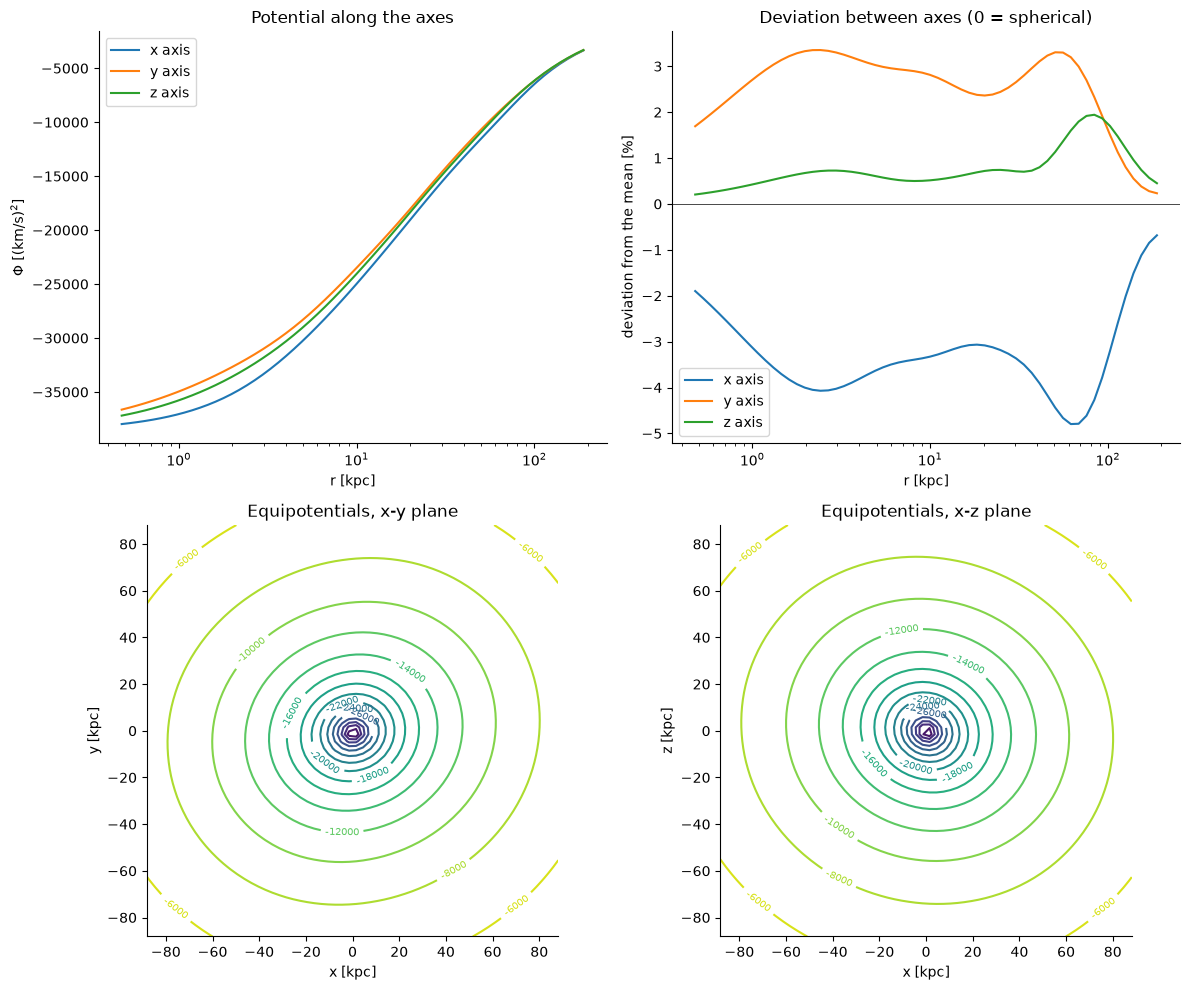

In [2]:
def build_SCF(file, N=10, L=4, plot=True):
    """
    Builds a galpy SCF (basis-function expansion) potential directly from the DM particles,
    with no spherical symmetry assumption, and optionally plots how spherical it is.

    N : number of radial terms
    L : number of angular terms (L = 0 is spherical)
    plot : whether to plot the potential along the axes and in two planes
    """
    ro, vo = 8.0, 220.0   # galpy's unit scales (kpc, km/s)

    with h5py.File(file, "r") as f:
        hdr = dict(f["Header"].attrs)
        pos = f["PartType1/Coordinates"][:]
        m = np.full(len(pos), hdr["MassTable"][1])

    h = hdr.get("HubbleParam", 1.0)
    L_unit = hdr.get("UnitLength_in_cm", 3.085678e21) * u.cm / h
    M_unit = hdr.get("UnitMass_in_g", 1.989e43) * u.g / h

    pos = pos * L_unit.to(u.kpc)
    m = m * M_unit.to(u.Msun)

    # Center on the particles (all masses are equal)
    x = pos - pos.mean(axis=0)
    r_part = np.sort(np.linalg.norm(x.value, axis=1))      # sorted particle radii in kpc

    # Scale radius of the basis: the median radius works as a starting point
    a_phys = np.median(r_part) * u.kpc

    # SCF works in galpy natural units
    x_nat = conversion.parse_length(x, ro=ro, vo=vo)
    m_nat = conversion.parse_mass(m, ro=ro, vo=vo)
    a_nat = conversion.parse_length(a_phys, ro=ro, vo=vo)

    # Expansion coefficients from the particles; pos must have shape (3, N_particles)
    Acos, Asin = scf_compute_coeffs_nbody(x_nat.T, N, L, mass=m_nat, a=a_nat)
    pot_scf = SCFPotential(Acos=Acos, Asin=Asin, a=a_nat, ro=ro, vo=vo)

    if plot:
        pot_unit = u.km**2 / u.s**2

        # --- Potential along the three coordinate axes ---
        # Radii from the 100th particle (as before, inside that it's noise) to the outermost one
        r_ax = np.geomspace(r_part[100], r_part[-1], 60) * u.kpc
        tiny = 1e-6 * r_ax            # galpy works in cylindrical coords, so the z axis needs R ~ 0
        zero = 0. * u.kpc

        Phi_x = evaluatePotentials(pot_scf, r_ax, zero, phi=0. * u.rad, quantity=True).to(pot_unit)
        Phi_y = evaluatePotentials(pot_scf, r_ax, zero, phi=90. * u.deg, quantity=True).to(pot_unit)
        Phi_z = evaluatePotentials(pot_scf, tiny, r_ax, phi=0. * u.rad, quantity=True).to(pot_unit)

        Phi_axes = {"x axis": Phi_x, "y axis": Phi_y, "z axis": Phi_z}
        Phi_mean = (Phi_x + Phi_y + Phi_z) / 3

        # --- Potential on a grid in the x-y and x-z planes ---
        lim = np.percentile(r_part, 90)                  # plot out to the 90th percentile radius
        g = np.linspace(-lim, lim, 60)                   # even number of points, so r = 0 is not on the grid
        X, Y = np.meshgrid(g, g)

        # x-y plane (z = 0): R = sqrt(x^2 + y^2), phi = arctan2(y, x)
        R_xy = np.hypot(X, Y).ravel() * u.kpc
        phi_xy = np.arctan2(Y, X).ravel() * u.rad
        Phi_xy = evaluatePotentials(pot_scf, R_xy, zero, phi=phi_xy, quantity=True)
        Phi_xy = Phi_xy.to_value(pot_unit).reshape(X.shape)

        # x-z plane (y = 0): R = |x|, phi = 0 for x > 0 and pi for x < 0, z = second axis
        R_xz = np.abs(X).ravel() * u.kpc
        phi_xz = np.where(X.ravel() >= 0, 0., np.pi) * u.rad
        Phi_xz = evaluatePotentials(pot_scf, R_xz, Y.ravel() * u.kpc, phi=phi_xz, quantity=True)
        Phi_xz = Phi_xz.to_value(pot_unit).reshape(X.shape)

        fig, ax = plt.subplots(2, 2, figsize=(12, 10))

        # Top left: the potential along each axis
        for name, Phi in Phi_axes.items():
            ax[0, 0].semilogx(r_ax.value, Phi.value, label=name)
        ax[0, 0].set(xlabel="r [kpc]", ylabel=r"$\Phi$ [(km/s)$^2$]", title="Potential along the axes")
        ax[0, 0].legend()

        # Top right: deviation of each axis from the mean of the three, in percent
        for name, Phi in Phi_axes.items():
            ax[0, 1].semilogx(r_ax.value, ((Phi - Phi_mean) / np.abs(Phi_mean)).decompose().value * 100,
                              label=name)
        ax[0, 1].axhline(0, color="k", lw=0.5)
        ax[0, 1].set(xlabel="r [kpc]", ylabel="deviation from the mean [%]",
                     title="Deviation between axes (0 = spherical)")
        ax[0, 1].legend()

        # Bottom row: equipotential contours; circles mean spherical
        for a, Phi_map, title, ylab in [(ax[1, 0], Phi_xy, "x-y plane", "y [kpc]"),
                                        (ax[1, 1], Phi_xz, "x-z plane", "z [kpc]")]:
            cs = a.contour(g, g, Phi_map, levels=15)
            a.clabel(cs, fontsize=7, fmt="%.0f")
            a.set(xlabel="x [kpc]", ylabel=ylab, title=f"Equipotentials, {title}", aspect="equal")

        plt.tight_layout()
        plt.show()

    return pot_scf

pot_scf = build_SCF("cutout_188106.hdf5", N=10, L=4)